In [1]:
import os
import importlib.util

MODEL_DIR = "../models"
allModelsPaths = list()

for (root,dirs,files) in os.walk('../models/',topdown=True):
  if 'model.py' in files:
    allModelsPaths.append(
      root + '/' + 'model.py'
    )
allModelsPaths

['../models/dogsVsCats/model.py',
 '../models/mnist/model.py',
 '../models/eMnist/model.py',
 '../models/fashionMnist/model.py']

In [2]:
def loadModelFromFile(path, funcName):
    spec = importlib.util.spec_from_file_location('loadModel', path)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    if hasattr(module, funcName):
        return getattr(module, funcName)()
    raise AttributeError(f"Module {path} does not have a function named {funcName}")

model, targetLayer = loadModelFromFile(
    allModelsPaths[1],
    'loadModel'
)

model

mnistModel(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
)

In [3]:
from gradcam import gradcam
from hirescam import hirescam
from ablationcam import ablationcam
from smoothgrad import smoothgrad
from grad import grad
from integratedgrad import integratedgrad

In [4]:
import torch
from torchvision import datasets
import pathlib
from torchvision.transforms import ToTensor
import matplotlib.pyplot as plt

In [5]:
pathToData = pathlib.Path("../data")
BATCH_SIZE = 64
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
trainDataset= datasets.MNIST(root=pathToData, train=True, download=True, transform=ToTensor())

In [6]:
idx = 1000
gcam = gradcam(
    trainDataset[idx][0],
    model,
    targetLayer,
    trainDataset[idx][1],
    #background=127
    #normalize=False
)
ablcam = ablationcam(
    trainDataset[idx][0],
    model,
    targetLayer,
    trainDataset[idx][1],
    #background=127
    #normalize=False
)

hcam = hirescam(
    trainDataset[idx][0],
    model,
    targetLayer,
    trainDataset[idx][1],
    #background=127
    #normalize=False
)
smoothgrad = smoothgrad(
    trainDataset[idx][0],
    model,
    trainDataset[idx][1],
    #background=127
    #normalize=False
)
gr = grad(
    trainDataset[idx][0],
    model,
    trainDataset[idx][1],
    #background=127
    #normalize=False
)
print(trainDataset[idx][0].shape)
i_grad = integratedgrad(
    trainDataset[idx][0],
    model,
    trainDataset[idx][1],
    #background=127
    #normalize=False
)
image = trainDataset[idx][0].cpu().detach().numpy().squeeze(0)

/home/jakub/Desktop/inz/algorythms/.venv/lib/python3.12/site-packages/torch/nn/modules/module.py:1842: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


torch.Size([1, 28, 28])
torch.Size([1, 1, 28, 28])
torch.Size([1, 1, 28, 28])
torch.Size([50, 1, 1, 1])
torch.Size([50, 1, 28, 28])


In [7]:
type(gr)

numpy.ndarray

Text(0.5, 1.0, 'integratedgrad')

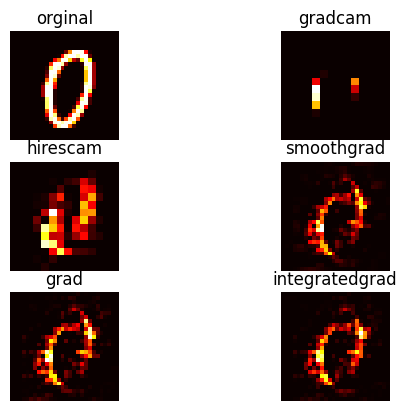

In [10]:
fig, axs = plt.subplots(3, 2)
axs[0][0].imshow(image, cmap='hot')
axs[0][0].axis(False)
axs[0][0].set_title('orginal')
axs[0][1].imshow(gcam, cmap='hot')
axs[0][1].axis(False)
axs[0][1].set_title('gradcam')
axs[1][0].imshow(hcam, cmap='hot')
axs[1][0].axis(False)
axs[1][0].set_title('hirescam')
axs[1][1].imshow(smoothgrad, cmap='hot')
axs[1][1].axis(False)
axs[1][1].set_title('smoothgrad')
axs[2][0].axis(False)
axs[2][0].imshow(gr, cmap='hot')
axs[2][0].set_title('grad')
axs[2][1].axis(False)
axs[2][1].imshow(i_grad, cmap='hot')
axs[2][1].set_title('integratedgrad')